r2_score

In [31]:
import pandas as pd


In [32]:
df=pd.read_csv('insurance.csv')
df.head(5)

,age,gender,bmi,children,smoker,region,charges
0,19,female,27.900,0,yes,southwest,16884.92400
1,18,male,33.770,1,no,southeast,1725.55230
2,28,male,33.000,3,no,southeast,4449.46200
3,33,male,22.705,0,no,northwest,21984.47061
4,32,male,28.880,0,no,northwest,3866.85520


In [33]:
from sklearn.preprocessing import LabelEncoder
df.isna().sum()
le=LabelEncoder()

df['gender']=le.fit_transform(df['gender'])
df['smoker']=le.fit_transform(df['smoker'])
df['region']=le.fit_transform(df['region'])

x=df.drop('charges',axis=1)
y=df['charges']

In [38]:
from sklearn.model_selection import train_test_split
x_train,x_test,y_train,y_test=train_test_split(x,y,test_size=0.2,random_state=42)


In [44]:
from sklearn.tree import DecisionTreeRegressor,plot_tree
from sklearn.metrics import mean_squared_error, r2_score
model=DecisionTreeRegressor(max_depth=3,random_state=42)
model.fit(x_train,y_train)
y_pred=model.predict(x_test)


In [48]:
r2=r2_score(y_test,y_pred)
mse=mean_squared_error(y_test,y_pred)

print("R2 Score:",r2)
print("Mean Squared Error:",mse)

R2 Score: 0.8530572866320028
Mean Squared Error: 22812669.85234084


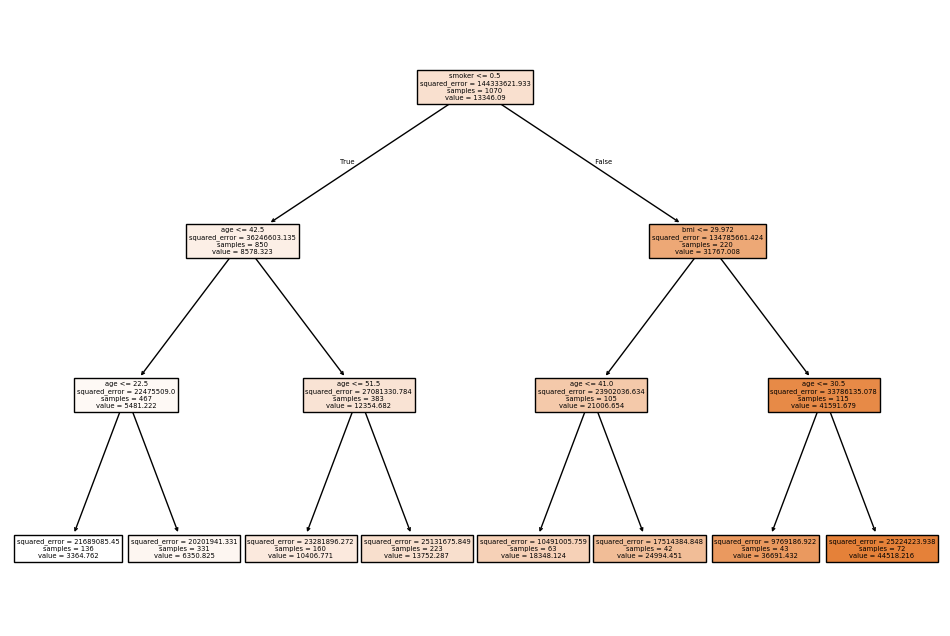

In [46]:
import matplotlib.pyplot as plt
plt.figure(figsize=(12,8))
plot_tree(model,filled=True,feature_names=x.columns)
plt.show()

In [67]:
import plotly.express as px
px.scatter(x=y_test,y=y_pred,title="Actual vs Predicted",labels={'x':'Actual Charges','y':'Predicted Charges'})



<Axes: xlabel='charges', ylabel='charges'>

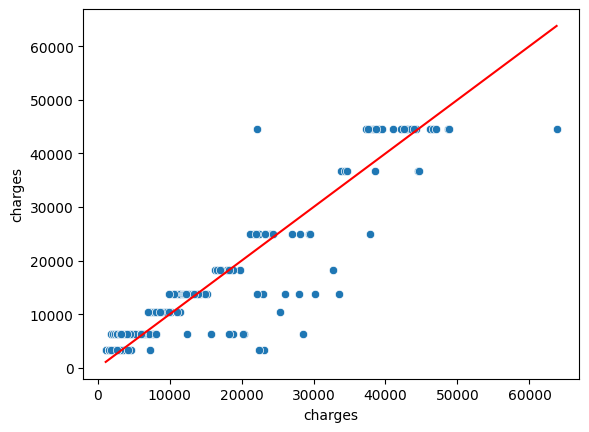

In [61]:
import seaborn as sns
sns.scatterplot(x=y_test,y=y_pred)
sns.lineplot(x=y_test,y=y_test,color='red')